In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("transaction_fraud_numerical_10000_rows.csv")


In [3]:
df.head(10)

,Transaction_ID,Customer_Age,Transaction_Amount,Transaction_Hour,Account_Age_Days,Num_Items,Avg_Transaction_30d,Distance_From_Home_KM,Failed_Transactions_7d,Fraud_Flag
0,108405,30.0,85.21,6.0,2432.0,2.0,45.36,1.58,0.0,0
1,100800,40.0,25.34,22.0,1009.0,4.0,20.02,18.12,0.0,0
2,109704,33.0,28.84,22.0,1036.0,3.0,30.06,0.90,0.0,0
3,105961,35.0,146.44,18.0,1248.0,1.0,63.66,9.52,1.0,0
4,108730,28.0,219.28,20.0,1173.0,4.0,79.94,7.19,1.0,0
5,107595,46.0,18.47,9.0,902.0,1.0,55.96,1.40,1.0,0
6,102796,31.0,41.31,15.0,388.0,3.0,53.84,48.81,0.0,0
7,105550,21.0,49.83,3.0,1706.0,2.0,40.98,7.46,0.0,0
8,101633,34.0,22.89,0.0,1526.0,4.0,51.57,3.58,1.0,0
9,103273,38.0,28.83,22.0,2742.0,2.0,72.09,5.61,0.0,0


In [4]:
df.shape

(10000, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Transaction_ID          10000 non-null  int64  
 1   Customer_Age            9965 non-null   float64
 2   Transaction_Amount      9958 non-null   float64
 3   Transaction_Hour        10000 non-null  float64
 4   Account_Age_Days        9969 non-null   float64
 5   Num_Items               10000 non-null  float64
 6   Avg_Transaction_30d     9966 non-null   float64
 7   Distance_From_Home_KM   9970 non-null   float64
 8   Failed_Transactions_7d  9974 non-null   float64
 9   Fraud_Flag              10000 non-null  int64  
dtypes: float64(8), int64(2)
memory usage: 781.4 KB


In [6]:
df.columns

Index(['Transaction_ID', 'Customer_Age', 'Transaction_Amount',
       'Transaction_Hour', 'Account_Age_Days', 'Num_Items',
       'Avg_Transaction_30d', 'Distance_From_Home_KM',
       'Failed_Transactions_7d', 'Fraud_Flag'],
      dtype='object')

In [7]:
df.describe()

,Transaction_ID,Customer_Age,Transaction_Amount,Transaction_Hour,Account_Age_Days,Num_Items,Avg_Transaction_30d,Distance_From_Home_KM,Failed_Transactions_7d,Fraud_Flag
count,10000.000000,9965.000000,9958.000000,10000.000000,9969.000000,10000.00000,9966.000000,9970.000000,9974.000000,10000.000000
mean,104954.296500,36.643452,76.234680,11.456200,1267.448691,3.22130,49.691646,11.104412,0.248847,0.049200
std,2856.507278,11.396288,101.119333,6.902887,729.025307,1.48167,36.697902,49.438704,0.493654,0.216296
min,100001.000000,18.000000,3.900000,0.000000,18.000000,1.00000,3.370000,0.000000,0.000000,0.000000
25%,102484.750000,29.000000,32.860000,5.000000,729.000000,2.00000,26.075000,2.360000,0.000000,0.000000
50%,104956.500000,36.000000,55.075000,11.000000,1132.000000,3.00000,40.050000,5.740000,0.000000,0.000000
75%,107428.250000,44.000000,91.600000,17.000000,1662.000000,4.00000,61.970000,11.370000,0.000000,0.000000
max,109900.000000,124.000000,3438.001736,23.000000,5000.000000,10.00000,753.060000,1179.248333,4.000000,1.000000


In [8]:
df.duplicated().sum()

np.int64(100)

In [9]:
df=df.drop_duplicates()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.shape

(9900, 10)

In [12]:
df.isnull().sum()

Transaction_ID             0
Customer_Age              35
Transaction_Amount        40
Transaction_Hour           0
Account_Age_Days          30
Num_Items                  0
Avg_Transaction_30d       34
Distance_From_Home_KM     30
Failed_Transactions_7d    25
Fraud_Flag                 0
dtype: int64

In [13]:
(df.isnull().sum()/len(df))*100

Transaction_ID            0.000000
Customer_Age              0.353535
Transaction_Amount        0.404040
Transaction_Hour          0.000000
Account_Age_Days          0.303030
Num_Items                 0.000000
Avg_Transaction_30d       0.343434
Distance_From_Home_KM     0.303030
Failed_Transactions_7d    0.252525
Fraud_Flag                0.000000
dtype: float64

In [14]:
df.isnull().sum().sum()

np.int64(194)

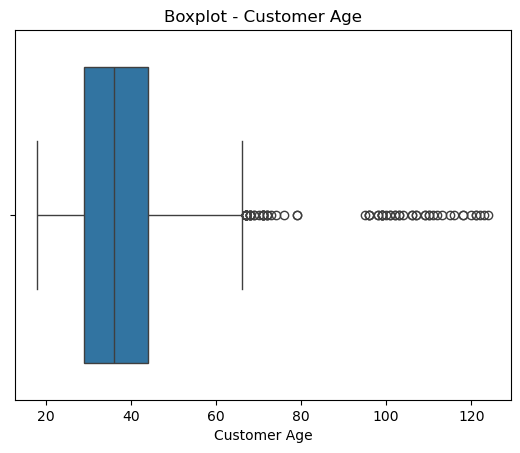

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df["Customer_Age"])
plt.title("Boxplot - Customer Age")
plt.xlabel("Customer Age")
plt.show()

In [16]:
Q1 = df["Customer_Age"].quantile(0.25)
Q3 = df["Customer_Age"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)

Q1: 29.0
Q3: 44.0
IQR: 15.0
Lower Limit: 6.5
Upper Limit: 66.5


In [17]:
print("Lower:", lower)
print("Upper:", upper)

print("Below Lower Limit:",
      (df["Customer_Age"] < lower).sum())

print("Above Upper Limit:",
      (df["Customer_Age"] > upper).sum())

Lower: 6.5
Upper: 66.5
Below Lower Limit: 0
Above Upper Limit: 73


In [18]:
lower = 6.5
upper = 66.5

print("Lower Limit:", lower)
print("Upper Limit:", upper)

print("Below Lower Limit:",
      (df["Customer_Age"] < lower).sum())

print("Above Upper Limit:",
      (df["Customer_Age"] > upper).sum())

Lower Limit: 6.5
Upper Limit: 66.5
Below Lower Limit: 0
Above Upper Limit: 73


In [19]:
outliers = df[
    (df["Customer_Age"] < lower) |
    (df["Customer_Age"] > upper)
]

print("Outliers Count:", len(outliers))
print(outliers["Customer_Age"].sort_values().to_list())

Outliers Count: 73
[67.0, 67.0, 67.0, 67.0, 67.0, 67.0, 67.0, 67.0, 67.0, 67.0, 67.0, 68.0, 68.0, 68.0, 68.0, 68.0, 69.0, 69.0, 70.0, 71.0, 71.0, 71.0, 71.0, 71.0, 71.0, 72.0, 72.0, 72.0, 73.0, 74.0, 76.0, 79.0, 79.0, 95.0, 96.0, 96.0, 96.0, 98.0, 98.0, 99.0, 99.0, 99.0, 99.0, 99.0, 100.0, 101.0, 101.0, 102.0, 102.0, 103.0, 103.0, 104.0, 106.0, 106.0, 107.0, 107.0, 109.0, 109.0, 110.0, 110.0, 111.0, 112.0, 113.0, 115.0, 116.0, 118.0, 118.0, 120.0, 121.0, 121.0, 122.0, 123.0, 124.0]


In [20]:
print("Mean:", df["Customer_Age"].mean())
print("Median:", df["Customer_Age"].median())
print("Skewness:", df["Customer_Age"].skew())

Mean: 36.659300557526606
Median: 36.0
Skewness: 1.1195312678752736


In [21]:
df["Customer_Age"]=df["Customer_Age"].fillna(df["Customer_Age"].median())

In [22]:
df.isnull().sum()

Transaction_ID             0
Customer_Age               0
Transaction_Amount        40
Transaction_Hour           0
Account_Age_Days          30
Num_Items                  0
Avg_Transaction_30d       34
Distance_From_Home_KM     30
Failed_Transactions_7d    25
Fraud_Flag                 0
dtype: int64

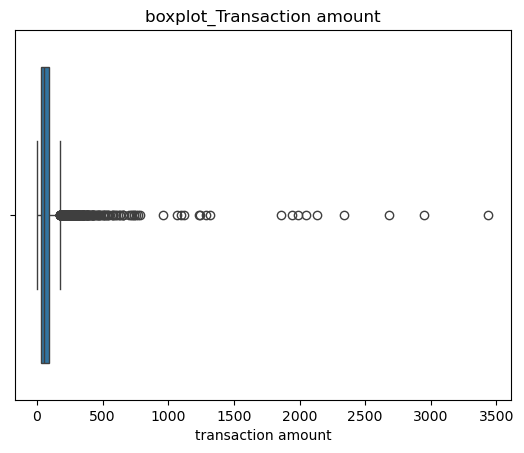

In [23]:
sns.boxplot(x=df["Transaction_Amount"])
plt.title("boxplot_Transaction amount")
plt.xlabel("transaction amount")
plt.show()

In [24]:
print("Q1:", df["Transaction_Amount"].quantile(0.25))
print("Median:", df["Transaction_Amount"].median())
print("Q3:", df["Transaction_Amount"].quantile(0.75))
print("Minimum:", df["Transaction_Amount"].min())
print("Maximum:", df["Transaction_Amount"].max())

Q1: 32.847500000000004
Median: 55.015
Q3: 91.335
Minimum: 3.9
Maximum: 3438.001735694705


In [25]:
Q1 = df["Transaction_Amount"].quantile(0.25)
Q3 = df["Transaction_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["Transaction_Amount"] < lower) |
    (df["Transaction_Amount"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Outliers Count:", len(outliers))


Q1: 32.847500000000004
Q3: 91.335
IQR: 58.48749999999999
Lower Limit: -54.883749999999985
Upper Limit: 179.06624999999997
Outliers Count: 625


In [26]:
print("Mean:", df["Transaction_Amount"].mean())
print("Median:", df["Transaction_Amount"].median())
print("Skewness:", df["Transaction_Amount"].skew())

Mean: 76.21740636510208
Median: 55.015
Skewness: 14.165991259986198


In [27]:
df["Transaction_Amount"]=df["Transaction_Amount"].fillna(df["Transaction_Amount"].median())

In [28]:
df.isnull().sum()

Transaction_ID             0
Customer_Age               0
Transaction_Amount         0
Transaction_Hour           0
Account_Age_Days          30
Num_Items                  0
Avg_Transaction_30d       34
Distance_From_Home_KM     30
Failed_Transactions_7d    25
Fraud_Flag                 0
dtype: int64

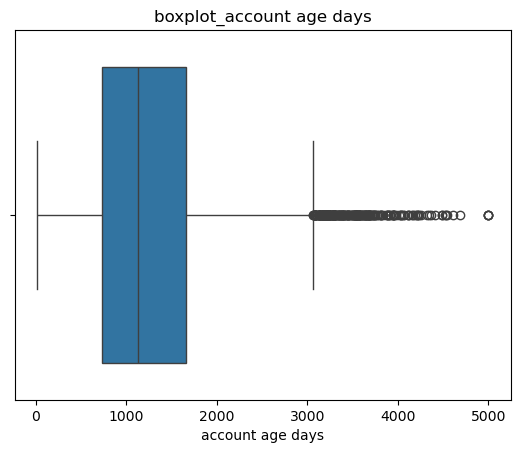

In [29]:
sns.boxplot(x=df["Account_Age_Days"])
plt.title("boxplot_account age days")
plt.xlabel("account age days")
plt.show()

In [30]:
Q1=df["Account_Age_Days"].quantile(0.25)
Q3=df["Account_Age_Days"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
print("q1",Q1)
print("q3",Q3)
print("iqr",IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)

q1 729.0
q3 1662.0
iqr 933.0
Lower Limit: -670.5
Upper Limit: 3061.5


In [31]:
outliers=df[(df["Account_Age_Days"]<lower)|(df["Account_Age_Days"]>upper)]
print("outliers count",len(outliers))
print(outliers["Account_Age_Days"].sort_values().tolist())

outliers count 245
[3064.0, 3065.0, 3069.0, 3070.0, 3079.0, 3084.0, 3084.0, 3085.0, 3085.0, 3088.0, 3091.0, 3092.0, 3094.0, 3096.0, 3100.0, 3119.0, 3129.0, 3129.0, 3130.0, 3130.0, 3131.0, 3132.0, 3134.0, 3135.0, 3136.0, 3140.0, 3146.0, 3146.0, 3147.0, 3155.0, 3164.0, 3165.0, 3166.0, 3168.0, 3172.0, 3172.0, 3174.0, 3175.0, 3176.0, 3177.0, 3180.0, 3182.0, 3186.0, 3190.0, 3191.0, 3191.0, 3195.0, 3195.0, 3199.0, 3208.0, 3211.0, 3212.0, 3213.0, 3216.0, 3217.0, 3218.0, 3219.0, 3221.0, 3224.0, 3225.0, 3230.0, 3233.0, 3234.0, 3235.0, 3238.0, 3238.0, 3244.0, 3247.0, 3249.0, 3249.0, 3251.0, 3251.0, 3252.0, 3257.0, 3259.0, 3260.0, 3283.0, 3284.0, 3284.0, 3284.0, 3286.0, 3288.0, 3289.0, 3290.0, 3292.0, 3293.0, 3296.0, 3299.0, 3299.0, 3300.0, 3300.0, 3304.0, 3305.0, 3306.0, 3311.0, 3313.0, 3319.0, 3333.0, 3339.0, 3339.0, 3341.0, 3348.0, 3352.0, 3358.0, 3362.0, 3362.0, 3367.0, 3368.0, 3380.0, 3384.0, 3387.0, 3391.0, 3395.0, 3396.0, 3402.0, 3405.0, 3409.0, 3419.0, 3431.0, 3433.0, 3439.0, 3445.0, 3450

In [32]:
print("Mean:", df["Account_Age_Days"].mean())
print("Median:", df["Account_Age_Days"].median())
print("Skewness:", df["Account_Age_Days"].skew())

Mean: 1268.0980749746707
Median: 1131.0
Skewness: 1.0603326751970565


In [33]:
df["Account_Age_Days"] = df["Account_Age_Days"].fillna(
    df["Account_Age_Days"].median()
)


In [34]:
print(df["Account_Age_Days"].isnull().sum())

0


In [35]:
df.isnull().sum()

Transaction_ID             0
Customer_Age               0
Transaction_Amount         0
Transaction_Hour           0
Account_Age_Days           0
Num_Items                  0
Avg_Transaction_30d       34
Distance_From_Home_KM     30
Failed_Transactions_7d    25
Fraud_Flag                 0
dtype: int64

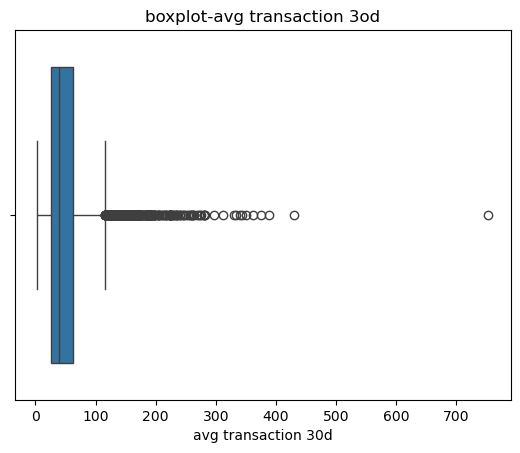

In [36]:
sns.boxplot(x=df["Avg_Transaction_30d"])
plt.title("boxplot-avg transaction 3od")
plt.xlabel("avg transaction 30d")
plt.show()

In [37]:
Q1 = df["Avg_Transaction_30d"].quantile(0.25)
Q3 = df["Avg_Transaction_30d"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)

Q1: 26.0425
Q3: 62.01
IQR: 35.9675
Lower Limit: -27.90875
Upper Limit: 115.96125


In [38]:
outliers=df[(df["Avg_Transaction_30d"]<lower)|(df["Avg_Transaction_30d"]>upper)]
print("outliers count",len(outliers))
print(outliers["Avg_Transaction_30d"].sort_values().to_list())

outliers count 518
[116.12, 116.16, 116.26, 116.31, 116.33, 116.38, 116.39, 116.66, 116.69, 116.73, 116.76, 116.86, 117.04, 117.11, 117.18, 117.24, 117.38, 117.38, 117.39, 117.48, 117.59, 117.75, 117.85, 118.03, 118.03, 118.29, 118.29, 118.3, 118.42, 118.42, 118.47, 118.78, 118.92, 119.0, 119.07, 119.11, 119.12, 119.26, 119.27, 119.59, 119.6, 119.77, 119.81, 119.88, 119.89, 119.93, 119.96, 119.98, 120.01, 120.08, 120.13, 120.14, 120.37, 120.37, 120.6, 120.79, 120.97, 121.18, 121.18, 121.22, 121.32, 121.32, 121.76, 121.78, 121.88, 122.05, 122.08, 122.09, 122.21, 122.27, 122.31, 122.34, 122.36, 122.36, 122.47, 122.53, 122.53, 122.57, 122.68, 122.71, 122.79, 122.83, 123.07, 123.14, 123.24, 123.26, 123.34, 123.34, 123.6, 123.68, 123.77, 123.83, 123.91, 123.94, 123.97, 123.98, 124.06, 124.07, 124.07, 124.09, 124.29, 124.36, 124.41, 124.55, 124.73, 124.75, 125.26, 125.42, 125.48, 125.56, 125.57, 125.59, 125.6, 125.74, 125.86, 125.96, 125.99, 126.06, 126.17, 126.2, 126.43, 126.7, 126.92, 126.

In [39]:
print("Mean:", df["Avg_Transaction_30d"].mean())
print("Median:", df["Avg_Transaction_30d"].median())
print("Skewness:", df["Avg_Transaction_30d"].skew())

Mean: 49.6964159740523
Median: 40.055
Skewness: 3.0434054813834375


In [40]:
df["Avg_Transaction_30d"] = df["Avg_Transaction_30d"].fillna(
    df["Avg_Transaction_30d"].median()
)

In [41]:
df.isnull().sum()

Transaction_ID             0
Customer_Age               0
Transaction_Amount         0
Transaction_Hour           0
Account_Age_Days           0
Num_Items                  0
Avg_Transaction_30d        0
Distance_From_Home_KM     30
Failed_Transactions_7d    25
Fraud_Flag                 0
dtype: int64

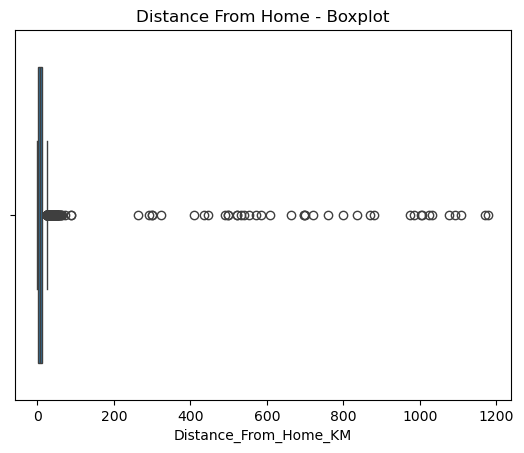

In [42]:
sns.boxplot(x=df["Distance_From_Home_KM"])
plt.title("Distance From Home - Boxplot")
plt.show()

In [43]:
Q1 = df["Distance_From_Home_KM"].quantile(0.25)
Q3 = df["Distance_From_Home_KM"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

outliers = df[
    (df["Distance_From_Home_KM"] < lower_limit) |
    (df["Distance_From_Home_KM"] > upper_limit)
]

print("Outliers Count:", len(outliers))

Q1: 2.36
Q3: 11.35
IQR: 8.99
Lower Limit: -11.125
Upper Limit: 24.835
Outliers Count: 499


In [44]:
print("Mean:", df["Distance_From_Home_KM"].mean())
print("Median:", df["Distance_From_Home_KM"].median())
print("Skewness:", df["Distance_From_Home_KM"].skew())

Mean: 10.92621968468573
Median: 5.72
Skewness: 17.774006796165004


In [45]:
df["Distance_From_Home_KM"] = df["Distance_From_Home_KM"].fillna(
    df["Distance_From_Home_KM"].median()
)

In [46]:
df.isnull().sum()

Transaction_ID             0
Customer_Age               0
Transaction_Amount         0
Transaction_Hour           0
Account_Age_Days           0
Num_Items                  0
Avg_Transaction_30d        0
Distance_From_Home_KM      0
Failed_Transactions_7d    25
Fraud_Flag                 0
dtype: int64

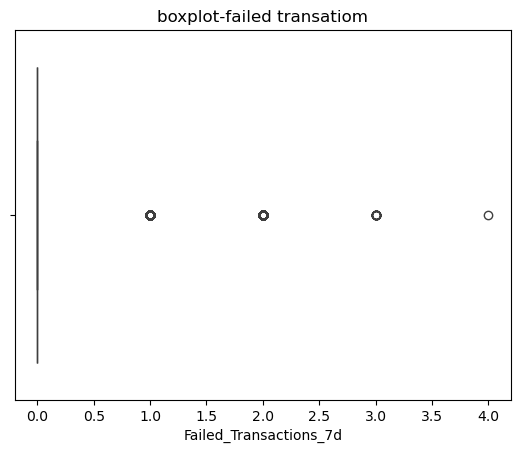

In [47]:
sns.boxplot(x=df["Failed_Transactions_7d"])
plt.title("boxplot-failed transatiom")
plt.show()

In [48]:
Q1 = df["Failed_Transactions_7d"].quantile(0.25)
Q3 = df["Failed_Transactions_7d"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

outliers = df[
    (df["Failed_Transactions_7d"] < lower_limit) |
    (df["Failed_Transactions_7d"] > upper_limit)
]

print("Outliers Count:", len(outliers))

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Limit: 0.0
Upper Limit: 0.0
Outliers Count: 2190


In [49]:
print("Mean:", df["Failed_Transactions_7d"].mean())
print("Median:", df["Failed_Transactions_7d"].median())
print("Mode:", df["Failed_Transactions_7d"].mode()[0])
print("Skewness:", df["Failed_Transactions_7d"].skew())

Mean: 0.2478987341772152
Median: 0.0
Mode: 0.0
Skewness: 1.9744496954198998


In [50]:
df["Failed_Transactions_7d"] = df["Failed_Transactions_7d"].fillna(
    df["Failed_Transactions_7d"].mode()[0]
)

In [51]:
df.isnull().sum()

Transaction_ID            0
Customer_Age              0
Transaction_Amount        0
Transaction_Hour          0
Account_Age_Days          0
Num_Items                 0
Avg_Transaction_30d       0
Distance_From_Home_KM     0
Failed_Transactions_7d    0
Fraud_Flag                0
dtype: int64

In [52]:
df.describe()

,Transaction_ID,Customer_Age,Transaction_Amount,Transaction_Hour,Account_Age_Days,Num_Items,Avg_Transaction_30d,Distance_From_Home_KM,Failed_Transactions_7d,Fraud_Flag
count,9900.000000,9900.000000,9900.000000,9900.000000,9900.000000,9900.000000,9900.000000,9900.000000,9900.000000,9900.000000
mean,104950.500000,36.656970,76.131740,11.452727,1267.682626,3.222626,49.663304,10.910443,0.247273,0.049596
std,2858.028166,11.381292,101.278659,6.906333,728.578761,1.480974,36.660968,47.754164,0.492870,0.217120
min,100001.000000,18.000000,3.900000,0.000000,18.000000,1.000000,3.370000,0.000000,0.000000,0.000000
25%,102475.750000,29.000000,32.887500,5.000000,730.000000,2.000000,26.120000,2.370000,0.000000,0.000000
50%,104950.500000,36.000000,55.015000,11.000000,1131.000000,3.000000,40.055000,5.720000,0.000000,0.000000
75%,107425.250000,44.000000,91.137500,17.000000,1661.250000,4.000000,61.942500,11.340000,0.000000,0.000000
max,109900.000000,124.000000,3438.001736,23.000000,5000.000000,10.000000,753.060000,1179.248333,4.000000,1.000000


In [53]:
print(df["Fraud_Flag"].value_counts())

Fraud_Flag
0    9409
1     491
Name: count, dtype: int64


In [54]:
print(df["Fraud_Flag"].value_counts(normalize=True) * 100)

Fraud_Flag
0    95.040404
1     4.959596
Name: proportion, dtype: float64


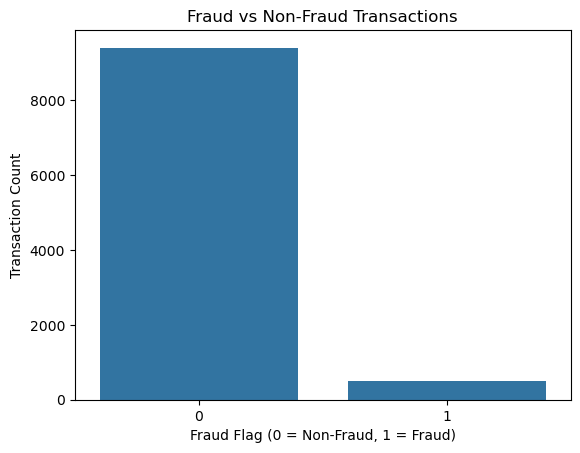

In [55]:
sns.countplot(x="Fraud_Flag", data=df)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Fraud Flag (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Transaction Count")

plt.show()

In [56]:
df["Fraud_Flag"].value_counts()

Fraud_Flag
0    9409
1     491
Name: count, dtype: int64

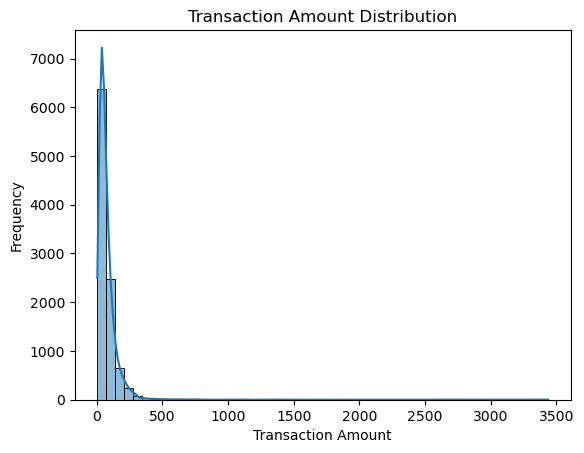

In [57]:
sns.histplot(df["Transaction_Amount"], bins=50, kde=True)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

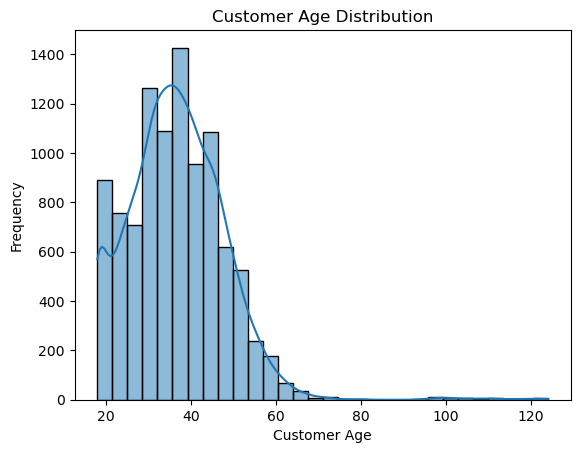

In [58]:
sns.histplot(df["Customer_Age"], bins=30, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Frequency")
plt.show()

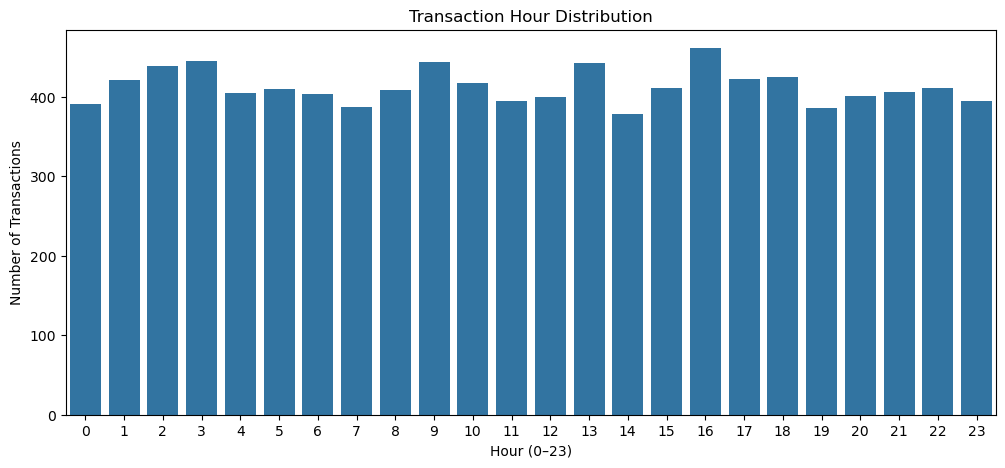

In [59]:
plt.figure(figsize=(12,5))

sns.countplot(
    x=df["Transaction_Hour"].astype(int)
)

plt.title("Transaction Hour Distribution")
plt.xlabel("Hour (0–23)")
plt.ylabel("Number of Transactions")

plt.xticks(ticks=range(24), labels=range(24))
plt.show()

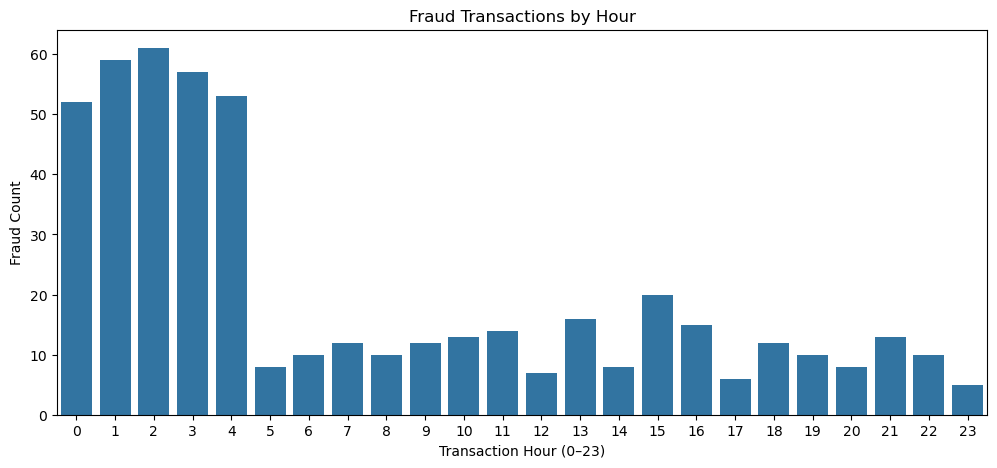

In [60]:
plt.figure(figsize=(12,5))

sns.countplot(
    x=df.loc[df["Fraud_Flag"] == 1, "Transaction_Hour"].astype(int)
)

plt.title("Fraud Transactions by Hour")
plt.xlabel("Transaction Hour (0–23)")
plt.ylabel("Fraud Count")

plt.xticks(ticks=range(24), labels=range(24))
plt.show()

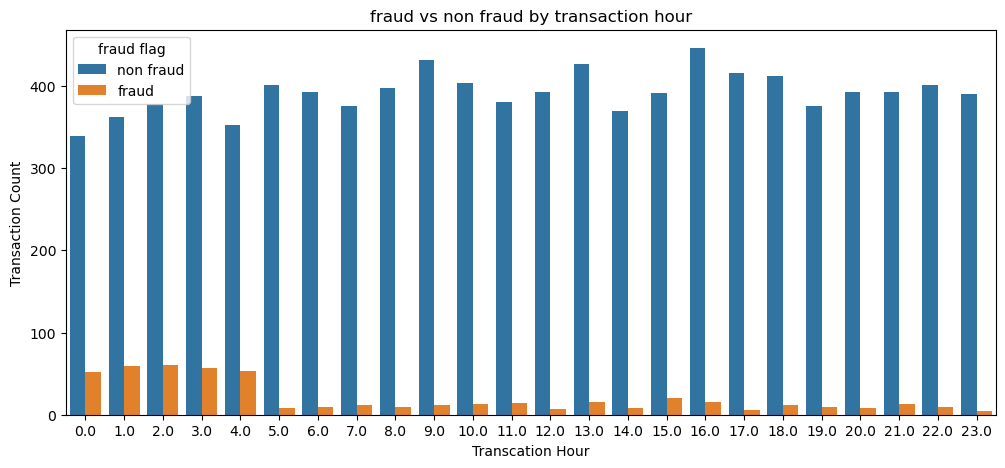

In [61]:
plt.figure(figsize=(12,5))
sns.countplot(x="Transaction_Hour",hue="Fraud_Flag",data=df)
plt.title("fraud vs non fraud by transaction hour")
plt.xlabel("Transcation Hour")
plt.ylabel("Transaction Count")
plt.legend(title="fraud flag",labels=["non fraud","fraud"])
plt.show()

In [62]:
fraud_rate=df.groupby("Transaction_Hour")["Fraud_Flag"].mean()*100
print(fraud_rate)

Transaction_Hour
0.0     13.299233
1.0     14.014252
2.0     13.895216
3.0     12.808989
4.0     13.086420
5.0      1.955990
6.0      2.481390
7.0      3.100775
8.0      2.450980
9.0      2.702703
10.0     3.117506
11.0     3.553299
12.0     1.750000
13.0     3.619910
14.0     2.116402
15.0     4.866180
16.0     3.253796
17.0     1.421801
18.0     2.830189
19.0     2.590674
20.0     1.995012
21.0     3.201970
22.0     2.433090
23.0     1.265823
Name: Fraud_Flag, dtype: float64


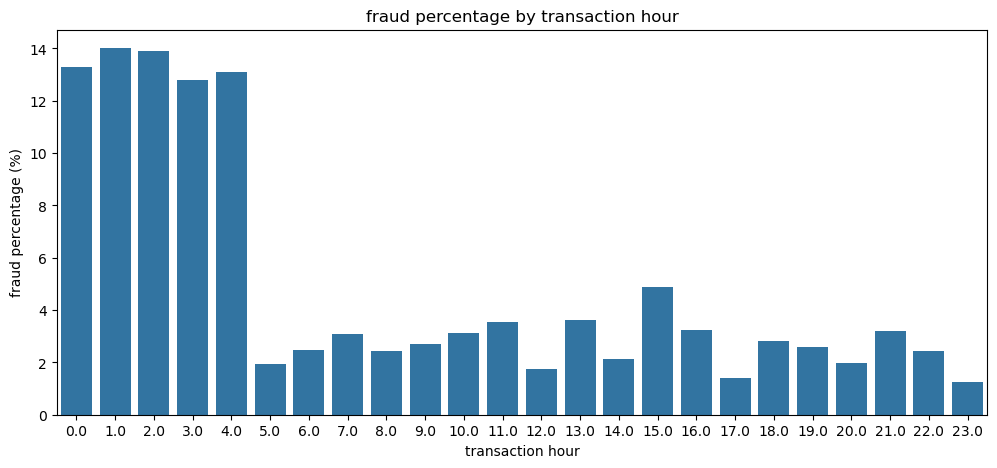

In [63]:
plt.figure(figsize=(12,5))
sns.barplot(x=fraud_rate.index,
            y=fraud_rate.values)
plt.title("fraud percentage by transaction hour")
plt.xlabel("transaction hour")
plt.ylabel("fraud percentage (%)")
plt.xticks(range(24))
plt.show()

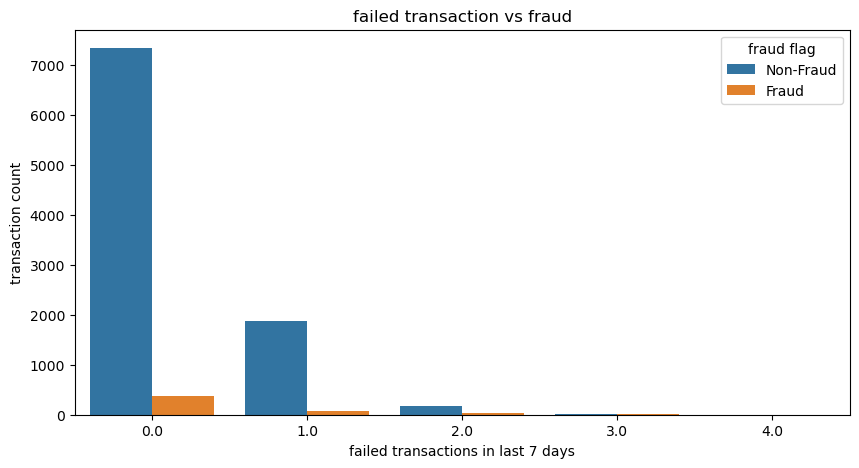

In [64]:
plt.figure(figsize=(10,5))
sns.countplot(x="Failed_Transactions_7d",hue="Fraud_Flag",data=df)
plt.title("failed transaction vs fraud")
plt.xlabel("failed transactions in last 7 days")
plt.ylabel("transaction count")
plt.legend(title="fraud flag",labels=["Non-Fraud","Fraud"])
plt.show()

In [65]:
failed_fraud_rate=df.groupby("Failed_Transactions_7d")["Fraud_Flag"].mean()*100
print(failed_fraud_rate)

Failed_Transactions_7d
0.0     4.850843
1.0     3.940635
2.0    16.279070
3.0    25.000000
4.0     0.000000
Name: Fraud_Flag, dtype: float64


In [66]:
df.groupby("Failed_Transactions_7d")["Fraud_Flag"].agg(Total_Transactions="count",Fraud_Count="sum",Fraud_Percentage="mean")

,Total_Transactions,Fraud_Count,Fraud_Percentage
Failed_Transactions_7d,,,
0.0,7710,374,0.048508
1.0,1954,77,0.039406
2.0,215,35,0.162791
3.0,20,5,0.250000
4.0,1,0,0.000000


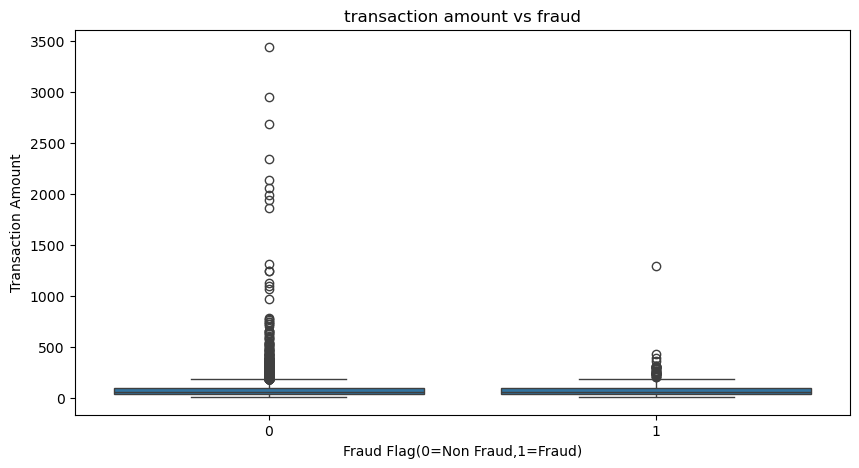

In [67]:
plt.figure(figsize=(10,5))
sns.boxplot(x="Fraud_Flag",y="Transaction_Amount",data=df)
plt.title("transaction amount vs fraud")
plt.xlabel("Fraud Flag(0=Non Fraud,1=Fraud)")
plt.ylabel("Transaction Amount")
plt.show()

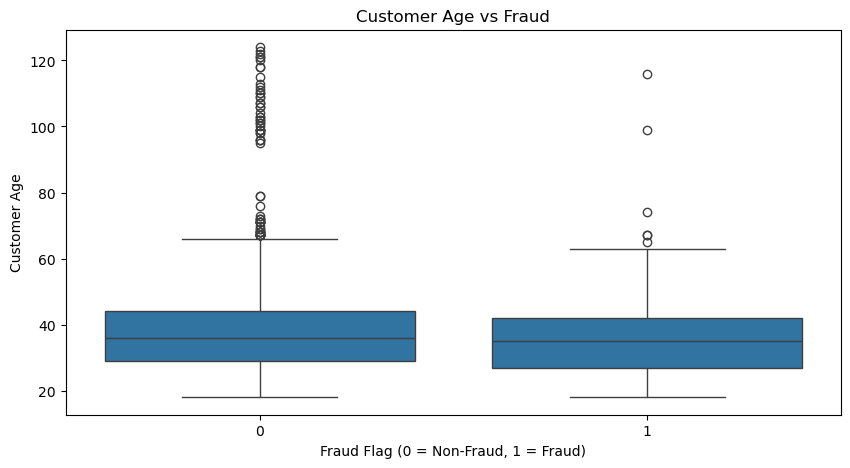

In [68]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x="Fraud_Flag",
    y="Customer_Age",
    data=df
)

plt.title("Customer Age vs Fraud")
plt.xlabel("Fraud Flag (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Customer Age")
plt.show()

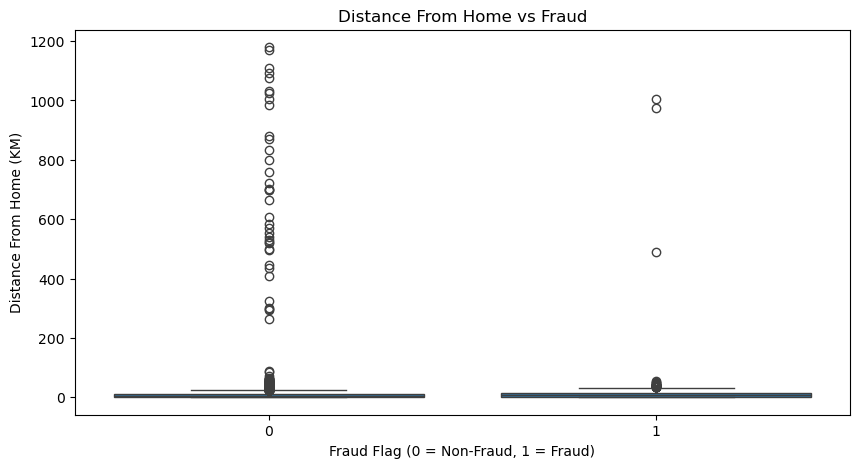

In [69]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x="Fraud_Flag",
    y="Distance_From_Home_KM",
    data=df
)

plt.title("Distance From Home vs Fraud")
plt.xlabel("Fraud Flag (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Distance From Home (KM)")
plt.show()

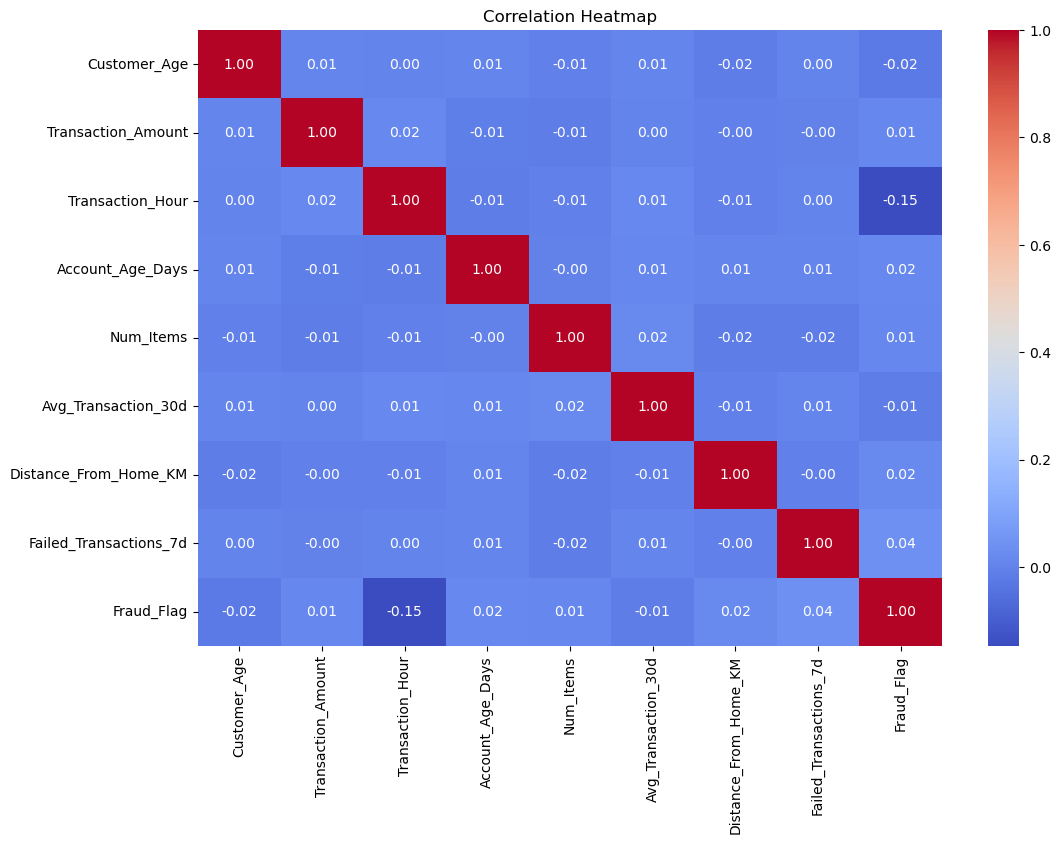

In [70]:
plt.figure(figsize=(12,8))

corr = df.drop("Transaction_ID", axis=1).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [71]:
x=df.drop(["Fraud_Flag","Transaction_ID"],axis=1)
y=df["Fraud_Flag"]
print("x shape:",x.shape)
print("y shape:",y.shape)

x shape: (9900, 8)
y shape: (9900,)


In [72]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,
    random_state=57,
    stratify=y)
print("x_train",x_train.shape)
print("x_test",x_test.shape)
print("y_train",y_train.shape)
print("y_test",y_test.shape)

x_train (7920, 8)
x_test (1980, 8)
y_train (7920,)
y_test (1980,)


In [73]:
print("Training Data:")
print(y_train.value_counts())

print("\nTraining Data Percentage:")
print(y_train.value_counts(normalize=True) * 100)

Training Data:
Fraud_Flag
0    7527
1     393
Name: count, dtype: int64

Training Data Percentage:
Fraud_Flag
0    95.037879
1     4.962121
Name: proportion, dtype: float64


In [74]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(
    max_iter=2000,
    random_state=57)
model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,57
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [75]:
y_pred=model.predict(x_test)
print(y_pred[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [76]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,y_pred)
print("accuracy",accuracy)
print("accuracy percentage",accuracy*100)

accuracy 0.9505050505050505
accuracy percentage 95.05050505050505


In [77]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[1882    0]
 [  98    0]]


In [78]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97      1882
           1       0.00      0.00      0.00        98

    accuracy                           0.95      1980
   macro avg       0.48      0.50      0.49      1980
weighted avg       0.90      0.95      0.93      1980



C:\Users\thanusha paidipati\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\thanusha paidipati\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\thanusha paidipati\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

In [79]:
model_balanced = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=57
)
model_balanced

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,57
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [80]:
model_balanced.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,57
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [81]:
y_pred_balanced = model_balanced.predict(x_test)

print(y_pred_balanced[:20])

[0 1 1 0 0 1 0 1 1 0 0 1 1 0 0 0 0 1 1 1]


In [82]:
from sklearn.metrics import accuracy_score

accuracy_balanced = accuracy_score(y_test, y_pred_balanced)

print("Balanced Model Accuracy:", accuracy_balanced)
print("Accuracy Percentage:", accuracy_balanced * 100)

Balanced Model Accuracy: 0.6101010101010101
Accuracy Percentage: 61.01010101010102


In [83]:
from sklearn.metrics import confusion_matrix

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

print(cm_balanced)

[[1145  737]
 [  35   63]]


In [84]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.97      0.61      0.75      1882
           1       0.08      0.64      0.14        98

    accuracy                           0.61      1980
   macro avg       0.52      0.63      0.44      1980
weighted avg       0.93      0.61      0.72      1980



In [85]:
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(
    random_state=57)
dt_model.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,57
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [86]:
y_pred_dt=dt_model.predict(x_test)
print(y_pred_dt[:20])

[0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0]


In [87]:
from sklearn.metrics import accuracy_score
accuracy_dt=accuracy_score(y_test,y_pred_dt)
print("Decision Tree Accuracy:", accuracy_dt)
print("Accuracy Percentage:", accuracy_dt * 100)

Decision Tree Accuracy: 0.9015151515151515
Accuracy Percentage: 90.15151515151516


In [88]:
from sklearn.metrics import confusion_matrix
cm_dt=confusion_matrix(y_test,y_pred_dt)
print(cm_dt)

[[1776  106]
 [  89    9]]


In [89]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.95      0.94      0.95      1882
           1       0.08      0.09      0.08        98

    accuracy                           0.90      1980
   macro avg       0.52      0.52      0.52      1980
weighted avg       0.91      0.90      0.91      1980



In [94]:
from sklearn.ensemble import RandomForestClassifier
rf_model=RandomForestClassifier(
    n_estimators=100,
    random_state=57)

In [96]:
rf_model.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [97]:
y_pred_rf=rf_model.predict(x_test)
print(y_pred_rf[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [98]:
from sklearn.metrics import accuracy_score
accuracy_rf=accuracy_score(y_test,y_pred_rf)
print("Random Forest Accuracy:", accuracy_rf)
print("Accuracy Percentage:", accuracy_rf * 100)

Random Forest Accuracy: 0.9494949494949495
Accuracy Percentage: 94.94949494949495


In [99]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[1880    2]
 [  98    0]]


In [100]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97      1882
           1       0.00      0.00      0.00        98

    accuracy                           0.95      1980
   macro avg       0.48      0.50      0.49      1980
weighted avg       0.90      0.95      0.93      1980



In [102]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=57
)

rf_balanced.fit(x_train, y_train)

y_pred_rf_balanced = rf_balanced.predict(x_test)

In [103]:
from sklearn.metrics import confusion_matrix

cm_rf_balanced = confusion_matrix(y_test, y_pred_rf_balanced)

print(cm_rf_balanced)

[[1882    0]
 [  98    0]]


In [104]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf_balanced))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97      1882
           1       0.00      0.00      0.00        98

    accuracy                           0.95      1980
   macro avg       0.48      0.50      0.49      1980
weighted avg       0.90      0.95      0.93      1980



C:\Users\thanusha paidipati\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\thanusha paidipati\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\thanusha paidipati\AppData\Local\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

In [106]:
import pandas as pd
feature_importance=pd.DataFrame({
    "Feature":x.columns,
    "Importance":rf_model.feature_importances_})
feature_importance=feature_importance.sort_values(
    by="Importance",
    ascending=False)
print(feature_importance)

                  Feature  Importance
6   Distance_From_Home_KM    0.184389
3        Account_Age_Days    0.165861
1      Transaction_Amount    0.165137
5     Avg_Transaction_30d    0.163406
2        Transaction_Hour    0.115083
0            Customer_Age    0.110038
4               Num_Items    0.063483
7  Failed_Transactions_7d    0.032605


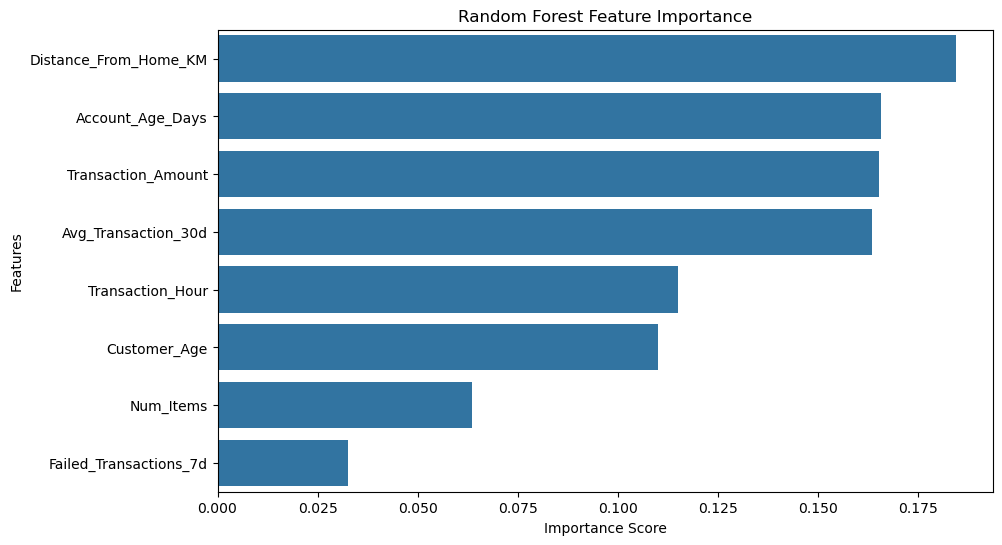

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [108]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Balanced Random Forest"
    ],
    "Accuracy": [95.05, 61.01, 90.15, 94.95, 95.05],
    "Fraud_Precision": [0, 8, 8, 0, 0],
    "Fraud_Recall": [0, 64, 9, 0, 0],
    "Fraud_F1_Score": [0, 14, 8, 0, 0]
})

print(model_comparison)

                          Model  Accuracy  Fraud_Precision  Fraud_Recall  \
0           Logistic Regression     95.05                0             0   
1  Balanced Logistic Regression     61.01                8            64   
2                 Decision Tree     90.15                8             9   
3                 Random Forest     94.95                0             0   
4        Balanced Random Forest     95.05                0             0   

   Fraud_F1_Score  
0               0  
1              14  
2               8  
3               0  
4               0  


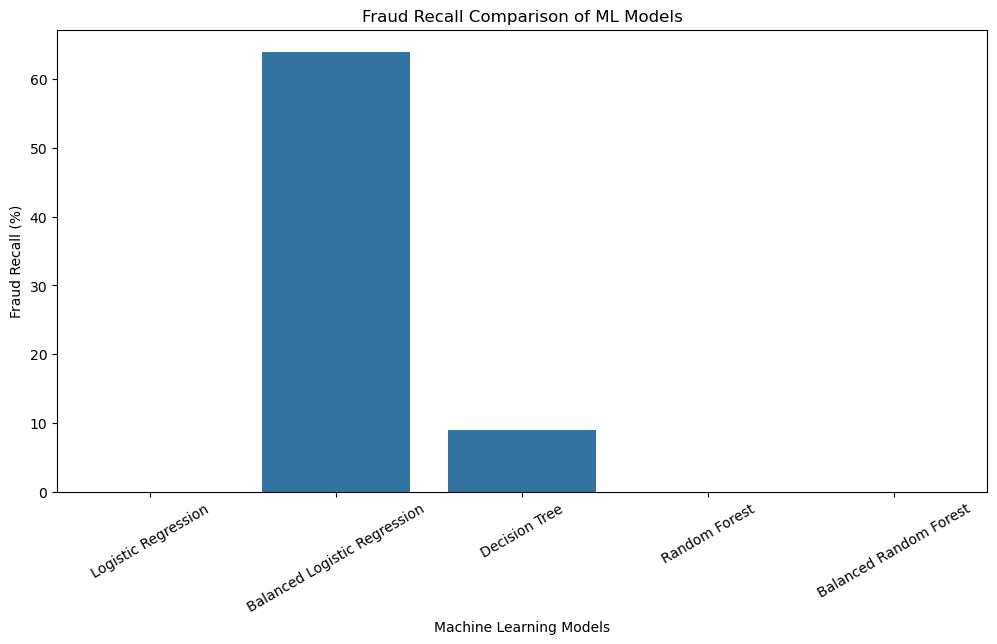

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    x="Model",
    y="Fraud_Recall",
    data=model_comparison
)

plt.title("Fraud Recall Comparison of ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Fraud Recall (%)")
plt.xticks(rotation=30)

plt.show()

In [112]:
df.to_csv("cleaned_bank_transactions.csv",index=False)